PART A: DATASET PREPARATION

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

In [3]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Number of training images:", len(x_train))
print("Number of testing images:", len(x_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Number of training images: 60000
Number of testing images: 10000


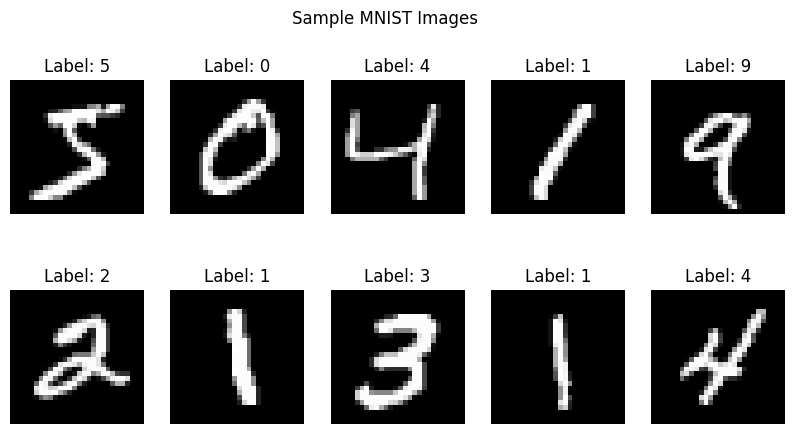

In [4]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample MNIST Images")
plt.show()

In [5]:
print("Image dimensions:", x_train[0].shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Data type:", x_train.dtype)

Image dimensions: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


In [6]:
# Normalize pixel values from [0, 255] to [-1, 1]
x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape images to (28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

print("Normalized image shape:", x_train.shape)
print("Minimum value:", x_train.min())
print("Maximum value:", x_train.max())

Normalized image shape: (60000, 28, 28, 1)
Minimum value: -1.0
Maximum value: 1.0


In [7]:
# Set batch size
BUFFER_SIZE = 60000
BATCH_SIZE = 128

# Create TensorFlow dataset
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)

train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

print("Dataset prepared successfully!")

Dataset prepared successfully!


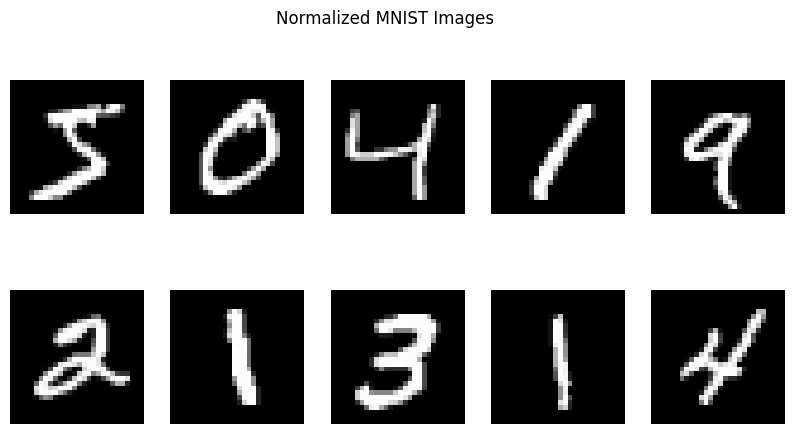

In [8]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.axis('off')

plt.suptitle("Normalized MNIST Images")
plt.show()

PART B: IMPLEMENTING THE THE GENERATOR AND DISCRIMINATOR

In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Sequential

NOISE_DIM = 100
IMAGE_SHAPE = (28, 28, 1)
BATCH_SIZE = 128

In [10]:
generator = Sequential([
    layers.Input(shape=(NOISE_DIM,)),

    layers.Dense(7 * 7 * 128),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Reshape((7, 7, 128)),

    layers.Conv2DTranspose(
        64, 4, strides=2, padding='same'
    ),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2DTranspose(
        1, 4, strides=2,
        padding='same', activation='tanh'
    )
], name="Generator")

generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 765,633 (2.92 MB)

 Trainable params: 765,633 (2.92 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
discriminator = Sequential([
    layers.Input(shape=IMAGE_SHAPE),

    layers.Conv2D(
        64, 4, strides=2, padding='same'
    ),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2D(
        128, 4, strides=2, padding='same'
    ),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Flatten(),
    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
], name="Discriminator")

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Keep Discriminator trainable
discriminator.trainable = True

gan = Sequential([
    generator,
    discriminator
], name="GAN")

gan.summary()

Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       765,633 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 904,194 (3.45 MB)

 Trainable params: 904,194 (3.45 MB)

 Non-trainable params: 0 (0.00 B)

PART C: GAN TRAINING AND PERFORMANCE MONITORING

In [13]:
EPOCHS = 50

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)

train_dataset = (
    train_dataset
    .shuffle(60000)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training dataset prepared successfully")
print("Batch size:", BATCH_SIZE)

Training dataset prepared successfully
Batch size: 128


In [14]:
cross_entropy = tf.keras.losses.BinaryCrossentropy()

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output), fake_output
    )

def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output), real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output
    )

    return real_loss + fake_loss

In [15]:
@tf.function
def train_step(real_images):

    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        # Generate fake images
        fake_images = generator(noise, training=True)

        # Discriminator predictions
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        # Calculate losses
        g_loss = generator_loss(fake_output)

        d_loss = discriminator_loss(
            real_output, fake_output
        )

    # Calculate gradients
    gen_gradients = gen_tape.gradient(
        g_loss, generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    # Update Generator
    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    # Update Discriminator
    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return g_loss, d_loss

Epoch 1/50 | Generator Loss: 1.4224 | Discriminator Loss: 0.7016
Epoch 2/50 | Generator Loss: 1.2321 | Discriminator Loss: 0.9489
Epoch 3/50 | Generator Loss: 1.2388 | Discriminator Loss: 0.9230
Epoch 4/50 | Generator Loss: 1.3679 | Discriminator Loss: 0.8467
Epoch 5/50 | Generator Loss: 1.3584 | Discriminator Loss: 0.9103
Epoch 6/50 | Generator Loss: 1.2626 | Discriminator Loss: 0.9725
Epoch 7/50 | Generator Loss: 1.1692 | Discriminator Loss: 1.0468
Epoch 8/50 | Generator Loss: 1.1301 | Discriminator Loss: 1.0650
Epoch 9/50 | Generator Loss: 1.1238 | Discriminator Loss: 1.0677
Epoch 10/50 | Generator Loss: 1.1319 | Discriminator Loss: 1.0559


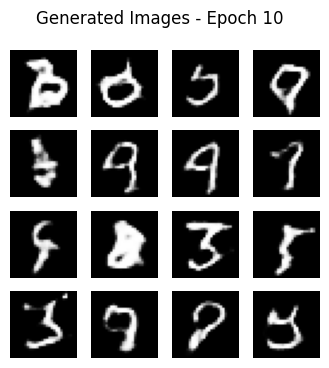

Epoch 11/50 | Generator Loss: 1.1457 | Discriminator Loss: 1.0383
Epoch 12/50 | Generator Loss: 1.1722 | Discriminator Loss: 1.0232
Epoch 13/50 | Generator Loss: 1.1975 | Discriminator Loss: 1.0011
Epoch 14/50 | Generator Loss: 1.2174 | Discriminator Loss: 0.9906
Epoch 15/50 | Generator Loss: 1.2440 | Discriminator Loss: 0.9769
Epoch 16/50 | Generator Loss: 1.2663 | Discriminator Loss: 0.9688
Epoch 17/50 | Generator Loss: 1.2810 | Discriminator Loss: 0.9644
Epoch 18/50 | Generator Loss: 1.2913 | Discriminator Loss: 0.9626
Epoch 19/50 | Generator Loss: 1.3085 | Discriminator Loss: 0.9543
Epoch 20/50 | Generator Loss: 1.3190 | Discriminator Loss: 0.9534


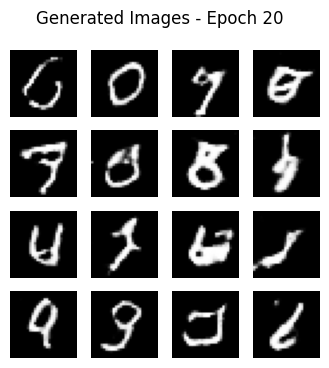

Epoch 21/50 | Generator Loss: 1.3287 | Discriminator Loss: 0.9515
Epoch 22/50 | Generator Loss: 1.3380 | Discriminator Loss: 0.9456
Epoch 23/50 | Generator Loss: 1.3465 | Discriminator Loss: 0.9457
Epoch 24/50 | Generator Loss: 1.3506 | Discriminator Loss: 0.9427
Epoch 25/50 | Generator Loss: 1.3566 | Discriminator Loss: 0.9449
Epoch 26/50 | Generator Loss: 1.3592 | Discriminator Loss: 0.9407
Epoch 27/50 | Generator Loss: 1.3659 | Discriminator Loss: 0.9428
Epoch 28/50 | Generator Loss: 1.3683 | Discriminator Loss: 0.9406
Epoch 29/50 | Generator Loss: 1.3707 | Discriminator Loss: 0.9439
Epoch 30/50 | Generator Loss: 1.3664 | Discriminator Loss: 0.9465


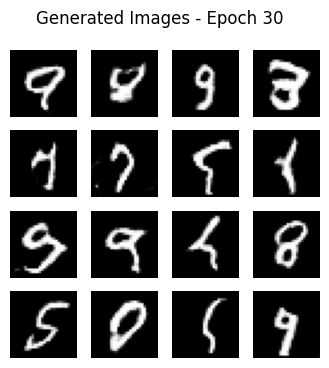

Epoch 31/50 | Generator Loss: 1.3693 | Discriminator Loss: 0.9451
Epoch 32/50 | Generator Loss: 1.3744 | Discriminator Loss: 0.9431
Epoch 33/50 | Generator Loss: 1.3755 | Discriminator Loss: 0.9449
Epoch 34/50 | Generator Loss: 1.3782 | Discriminator Loss: 0.9476
Epoch 35/50 | Generator Loss: 1.3805 | Discriminator Loss: 0.9437
Epoch 36/50 | Generator Loss: 1.3780 | Discriminator Loss: 0.9483
Epoch 37/50 | Generator Loss: 1.3742 | Discriminator Loss: 0.9480
Epoch 38/50 | Generator Loss: 1.3814 | Discriminator Loss: 0.9500
Epoch 39/50 | Generator Loss: 1.3723 | Discriminator Loss: 0.9578
Epoch 40/50 | Generator Loss: 1.3788 | Discriminator Loss: 0.9478


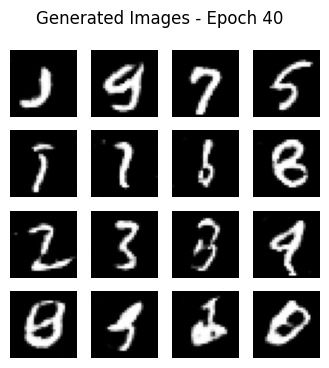

Epoch 41/50 | Generator Loss: 1.3806 | Discriminator Loss: 0.9526
Epoch 42/50 | Generator Loss: 1.3719 | Discriminator Loss: 0.9587
Epoch 43/50 | Generator Loss: 1.3729 | Discriminator Loss: 0.9587
Epoch 44/50 | Generator Loss: 1.3735 | Discriminator Loss: 0.9574
Epoch 45/50 | Generator Loss: 1.3687 | Discriminator Loss: 0.9620
Epoch 46/50 | Generator Loss: 1.3728 | Discriminator Loss: 0.9621
Epoch 47/50 | Generator Loss: 1.3715 | Discriminator Loss: 0.9634
Epoch 48/50 | Generator Loss: 1.3652 | Discriminator Loss: 0.9679
Epoch 49/50 | Generator Loss: 1.3628 | Discriminator Loss: 0.9650
Epoch 50/50 | Generator Loss: 1.3745 | Discriminator Loss: 0.9667


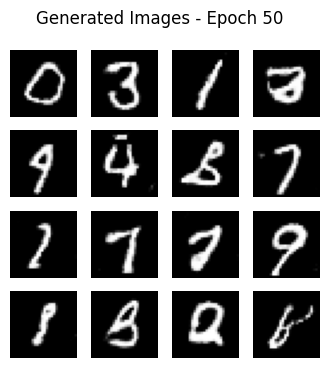

In [18]:
generator_losses = []
discriminator_losses = []

def generate_images(model, epoch):
    noise = tf.random.normal([16, NOISE_DIM])
    predictions = model(noise, training=False)
    plt.figure(figsize=(4, 4))
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0] * 0.5 + 0.5, cmap='gray')
        plt.axis('off')
    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.show()

for epoch in range(EPOCHS):

    total_g_loss = 0
    total_d_loss = 0
    batches = 0

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        total_g_loss += float(g_loss)
        total_d_loss += float(d_loss)

        batches += 1

    avg_g_loss = total_g_loss / batches
    avg_d_loss = total_d_loss / batches

    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {avg_g_loss:.4f} | "
        f"Discriminator Loss: {avg_d_loss:.4f}"
    )

    if (epoch + 1) % 10 == 0:
        generate_images(generator, epoch + 1)

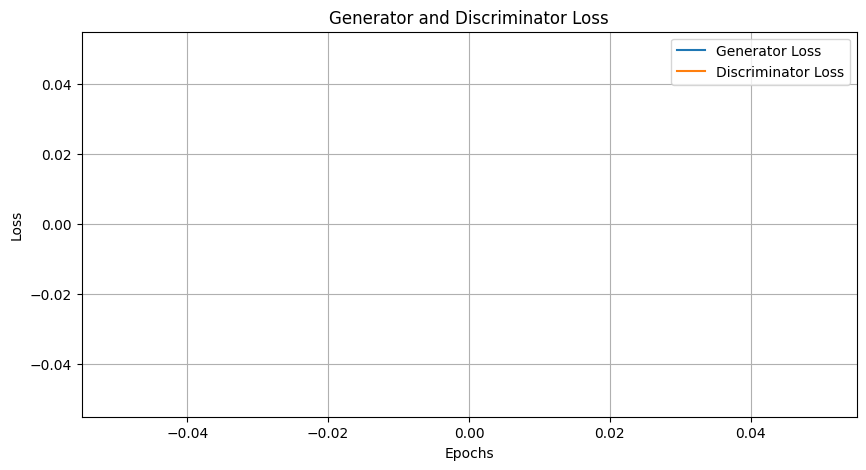

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(generator_losses, label='Generator Loss')
plt.plot(discriminator_losses, label='Discriminator Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Generator and Discriminator Loss')
plt.legend()
plt.grid(True)
plt.show()

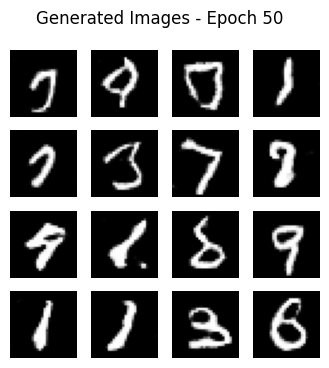

In [20]:
def generate_images(model, epoch):
    noise = tf.random.normal([16, NOISE_DIM])
    predictions = model(noise, training=False)
    plt.figure(figsize=(4, 4))
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0] * 0.5 + 0.5, cmap='gray')
        plt.axis('off')
    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.show()

generate_images(generator, EPOCHS)

PART D: IMAGE GENERATION, VISUALIZATION AND EXPERIMENT MANAGEMENT

In [21]:
# Generate 16 random noise vectors
noise = tf.random.normal([16, NOISE_DIM])

# Generate synthetic images
generated_images = generator(noise, training=False)

print("Generated images shape:", generated_images.shape)

Generated images shape: (16, 28, 28, 1)


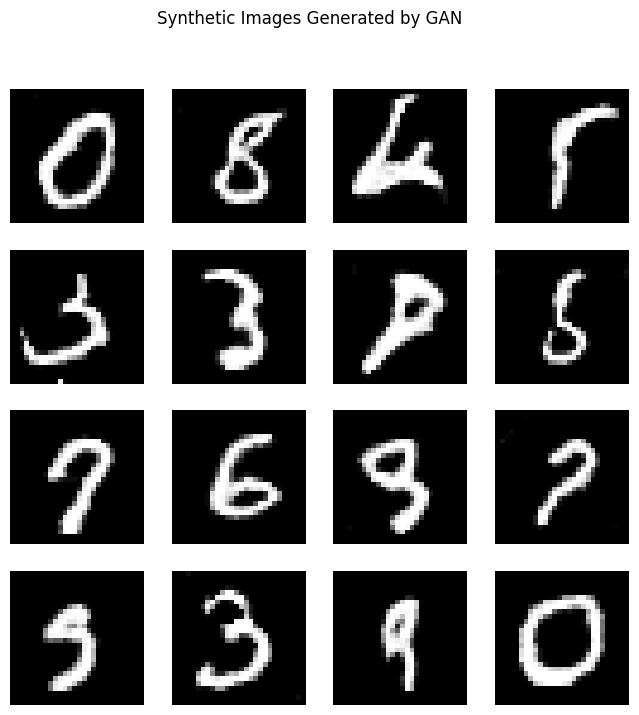

In [22]:
plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        generated_images[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )

    plt.axis('off')

plt.suptitle("Synthetic Images Generated by GAN")
plt.show()

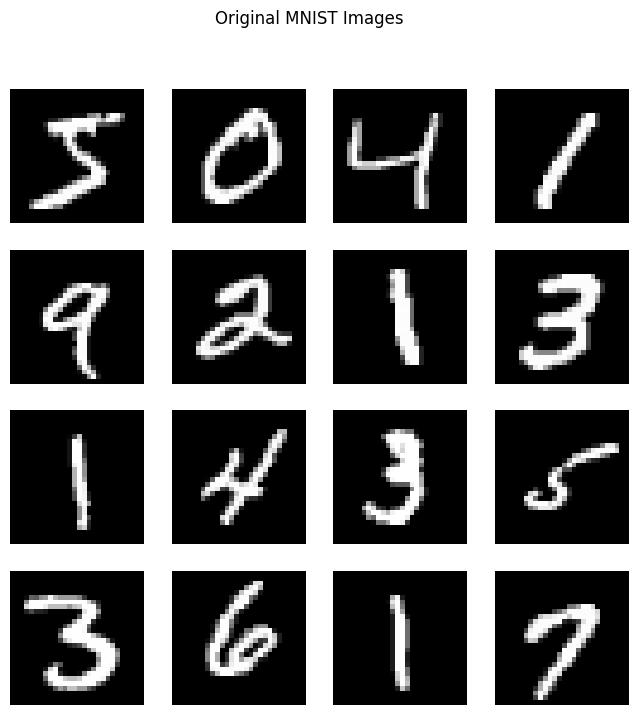

In [23]:
plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        x_train[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )

    plt.axis('off')

plt.suptitle("Original MNIST Images")
plt.show()

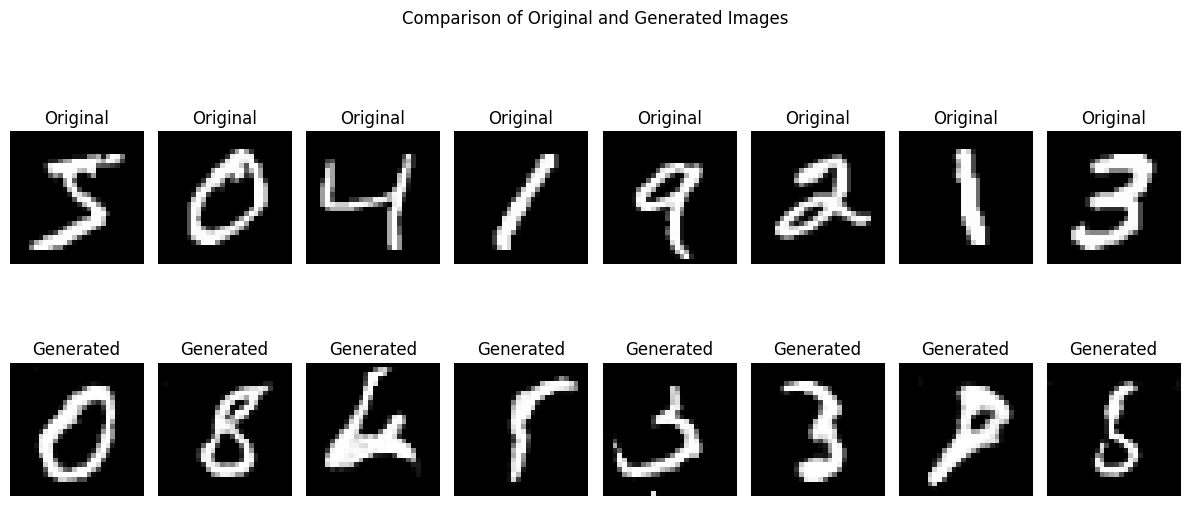

In [24]:
plt.figure(figsize=(12, 6))

for i in range(8):

    # Original image
    plt.subplot(2, 8, i + 1)
    plt.imshow(
        x_train[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )
    plt.title("Original")
    plt.axis('off')

    # Generated image
    plt.subplot(2, 8, i + 9)
    plt.imshow(
        generated_images[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )
    plt.title("Generated")
    plt.axis('off')

plt.suptitle("Comparison of Original and Generated Images")
plt.tight_layout()
plt.show()

In [25]:
# Calculate pixel statistics of generated images

generated_array = generated_images.numpy()

print("Generated image shape:", generated_array.shape)
print("Minimum pixel value:", generated_array.min())
print("Maximum pixel value:", generated_array.max())
print("Mean pixel value:", generated_array.mean())
print("Standard deviation:", generated_array.std())

Generated image shape: (16, 28, 28, 1)
Minimum pixel value: -1.0
Maximum pixel value: 0.9999914
Mean pixel value: -0.7391586
Standard deviation: 0.6163431
